Before starting, upload the .SAFE.zip file of the before and after image of the given district on your Google Drive.
Also download Sentinel Toolboxes for Linux 64-bit (Main Download) from this link : -https://step.esa.int/main/download/snap-download/, and upload the downloaded .sh file on your google drive as well.
If at any point you ran out of RAM, go to runtime and click Restart session. We are saving our output after every step so it wont affect the execution of further cells. Some cells(usually for saving the output on disc) might take around 30 minutes to execute.

INSTALLING DEPENDENCIES

In [ ]:
# ============================================================
# 1. Check Python and Java versions
# ============================================================
!python --version
import sys
print(sys.version)
!java -version

# ============================================================
# 2. Install Linux dependencies
# ============================================================
!apt-get update -qq
!apt-get install -y -qq wget unzip curl
!which java

# ============================================================
# 3. Mount Drive, COPY installer to local disk, make executable
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

DRIVE_INSTALLER = "/content/drive/MyDrive/esa-snap_sentinel_linux-14.0.0.sh"
LOCAL_INSTALLER = "/content/esa-snap_sentinel_linux-14.0.0.sh"

!cp "{DRIVE_INSTALLER}" "{LOCAL_INSTALLER}"
!chmod +x "{LOCAL_INSTALLER}"
!ls -lh "{LOCAL_INSTALLER}"
!file "{LOCAL_INSTALLER}"

# ============================================================
# 4. Run the installer locally (only once)
# ============================================================
!rm -rf /opt/snap
!mkdir -p /opt/snap
!bash "{LOCAL_INSTALLER}" -q -dir /opt/snap

# ============================================================
# 5. Check that SNAP actually installed
# ============================================================
!find /opt/snap -maxdepth 2 -type f | head -50
!ls -lah /opt/snap
!/opt/snap/bin/gpt -h

# ============================================================
# 6. Check that Sentinel-1 operators exist
# ============================================================
!/opt/snap/bin/gpt -h Apply-Orbit-File

# ============================================================
# 7. Configure esa_snappy (Python <-> SNAP bridge)
# ============================================================
import sys
print(sys.executable)

!/usr/bin/python3 -m pip install esa-snappy
!find /opt/snap -iname "*snappy-conf*" -o -iname "*snappyutil*"
!/opt/snap/bin/snappy-conf /usr/bin/python3

# ============================================================
# 8. Test Python <-> SNAP integration
# ============================================================
!/usr/bin/python3 -c "import esa_snappy; print(esa_snappy.__file__)"
!/usr/bin/python3 -c "from esa_snappy import ProductIO; print('SNAP Python API OK')"

Python 3.13.15
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[0.032s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.032s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12" 2026-07-21
OpenJDK Runtime Environment (build 21.0.12+8-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12+8-1-24.04-Ubuntu, mixed mode, sharing)
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../libcurl4-openssl-dev_8.5.0-2ubuntu10.15_amd64.deb ...
Unpacking libcurl4-openssl-dev:amd64 (8.5.0-2ubuntu10.15) over (8.5.0-2ubuntu10.13) ...


EXTRACTING THE BEFORE AND AFTER TILE IMAGES

In [ ]:
import zipfile
import os

before_zip = "/content/drive/MyDrive/sentinel1_downloads/DHUBRI/2024/before/DHUBRI_2024-03-08_Sentinel1_before.zip"
after_zip  = "/content/drive/MyDrive/sentinel1_downloads/DHUBRI/2024/during/DHUBRI_2024-06-12_Sentinel1_during_1.zip"
before_dir = "/content/before"
after_dir  = "/content/after"

with zipfile.ZipFile(before_zip, "r") as z:
    z.extractall(before_dir)

with zipfile.ZipFile(after_zip, "r") as z:
    z.extractall(after_dir)

print("Extraction complete!")

Extraction complete!


VISUALISING THE TILES

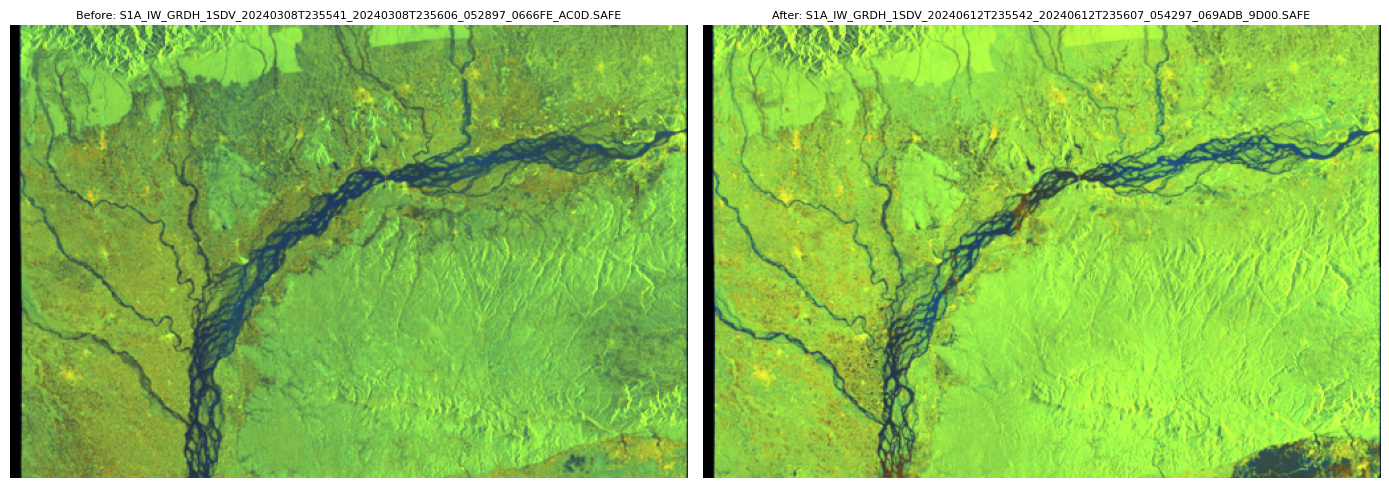

In [ ]:
import glob, os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# reuse your existing variables
dirs = {"Before": before_dir, "After": after_dir}

fig, axes = plt.subplots(1, len(dirs), figsize=(7*len(dirs), 7))

for ax, (label, d) in zip(axes, dirs.items()):
    safe_dirs = glob.glob(os.path.join(d, "*.SAFE"))
    if not safe_dirs:
        ax.text(0.5, 0.5, f"no .SAFE folder found in {d}", ha="center")
        ax.axis("off")
        continue

    safe_dir = safe_dirs[0]
    quicklook = glob.glob(os.path.join(safe_dir, "preview", "quick-look.png"))
    name = os.path.basename(safe_dir)

    if quicklook:
        img = Image.open(quicklook[0])
        ax.imshow(np.fliplr(np.array(img)))
        ax.set_title(f"{label}: {name}", fontsize=8)
    else:
        ax.text(0.5, 0.5, "no quicklook found", ha="center")
    ax.axis("off")

plt.tight_layout()
plt.show()

SOME STATISTICS

In [ ]:
from esa_snappy import ProductIO

before_safe = glob.glob("/content/before/**/*.SAFE", recursive=True)
after_safe  = glob.glob("/content/after/**/*.SAFE", recursive=True)
before = ProductIO.readProduct(before_safe[0])
after  = ProductIO.readProduct(after_safe[0])
print("BEFORE")
print("Name:", before.getName())
print("Product type:", before.getProductType())
print("Width:", before.getSceneRasterWidth())
print("Height:", before.getSceneRasterHeight())
print("Bands:", list(before.getBandNames()))

print("\nAFTER")
print("Name:", after.getName())
print("Product type:", after.getProductType())
print("Width:", after.getSceneRasterWidth())
print("Height:", after.getSceneRasterHeight())
print("Bands:", list(after.getBandNames()))

BEFORE
Name: S1A_IW_GRDH_1SDV_20240308T235541_20240308T235606_052897_0666FE_AC0D
Product type: GRD
Width: 25678
Height: 16736
Bands: ['Amplitude_VH', 'Intensity_VH', 'Amplitude_VV', 'Intensity_VV']

AFTER
Name: S1A_IW_GRDH_1SDV_20240612T235542_20240612T235607_054297_069ADB_9D00
Product type: GRD
Width: 25679
Height: 16736
Bands: ['Amplitude_VH', 'Intensity_VH', 'Amplitude_VV', 'Intensity_VV']


create an output directory

In [ ]:
import os

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

print("Output directory:", output_dir)

Output directory: /content/snap_outputs


Step 1A — Apply Orbit to Before Flood

In [ ]:
from esa_snappy import GPF, HashMap

orbit_params_before = HashMap()

before_orbit = GPF.createProduct(
    "Apply-Orbit-File",
    orbit_params_before,
    before
)

print("Before orbit processing completed.")
print("Product:", before_orbit)

Before orbit processing completed.
Product: org.esa.snap.core.datamodel.Product[name=S1A_IW_GRDH_1SDV_20240308T235541_20240308T235606_052897_0666FE_AC0D_Orb]


Step 1B — Apply Orbit to After Flood

In [ ]:
orbit_params_after = HashMap()

after_orbit = GPF.createProduct(
    "Apply-Orbit-File",
    orbit_params_after,
    after
)

print("After orbit processing completed.")
print("Product:", after_orbit)

After orbit processing completed.
Product: org.esa.snap.core.datamodel.Product[name=S1A_IW_GRDH_1SDV_20240612T235542_20240612T235607_054297_069ADB_9D00_Orb]


Step 1C - Save

In [ ]:
import os
from esa_snappy import ProductIO

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

before_orbit_path = os.path.join(output_dir, "before_orbit.dim")
after_orbit_path  = os.path.join(output_dir, "after_orbit.dim")

ProductIO.writeProduct(before_orbit, before_orbit_path, "BEAM-DIMAP")
ProductIO.writeProduct(after_orbit, after_orbit_path, "BEAM-DIMAP")

print("Before orbit saved:", before_orbit_path)
print("After orbit saved :", after_orbit_path)

Before orbit saved: /content/snap_outputs/before_orbit.dim
After orbit saved : /content/snap_outputs/after_orbit.dim


Step 1D - Visualise

['Amplitude_VH.hdr', 'Amplitude_VH.img', 'Amplitude_VV.hdr', 'Amplitude_VV.img', 'tie_point_grids', 'vector_data']


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


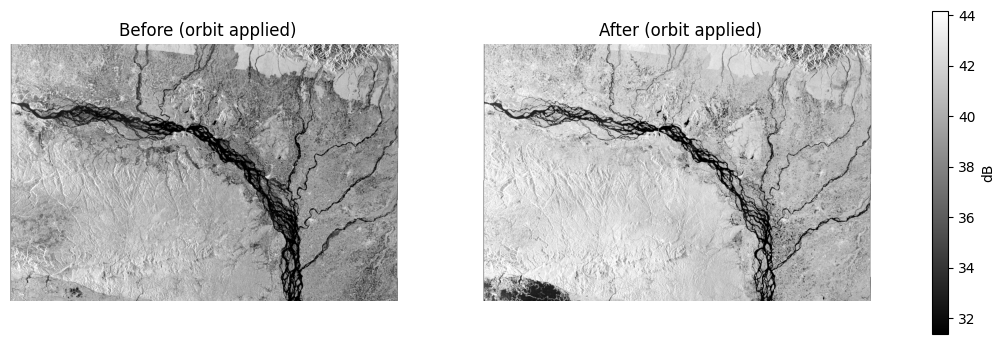

In [ ]:
import os, glob
import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

# BEAM-DIMAP stores each band as an ENVI .img file inside the .data folder
print(sorted(os.listdir(f"{output_dir}/before_orbit.data")))

def load_preview(dim_name, band="Amplitude_VH", scale=20):
    """Read a heavily downsampled version of one band and convert to dB."""
    img = f"{output_dir}/{dim_name}.data/{band}.img"
    with rasterio.open(img) as src:
        h, w = src.height // scale, src.width // scale
        arr = src.read(1, out_shape=(h, w), resampling=Resampling.average).astype("float32")
    arr[arr <= 0] = np.nan
    return 20 * np.log10(arr)          # amplitude -> dB (use 10*log10 for intensity)

before_db = load_preview("before_orbit")
after_db  = load_preview("after_orbit")

# Stretch contrast using percentiles so the image isn't washed out
vmin, vmax = np.nanpercentile(np.concatenate([before_db.ravel(), after_db.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, title in zip(ax, [before_db, after_db], ["Before (orbit applied)", "After (orbit applied)"]):
    im = a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(title); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="dB")
plt.show()

Step-2 Calibration

In [ ]:
from esa_snappy import GPF, HashMap

cal_params_before = HashMap()

cal_params_before.put("outputSigmaBand", False)
cal_params_before.put("outputBetaBand", False)
cal_params_before.put("outputGammaBand", True)

cal_params_before.put("selectedPolarisations", "VH")

before_gamma0 = GPF.createProduct(
    "Calibration",
    cal_params_before,
    before_orbit
)

print("Before Gamma0 calibration completed.")
print("Product:", before_gamma0)

Before Gamma0 calibration completed.
Product: org.esa.snap.core.datamodel.Product[name=before_orbit_Cal]


In [ ]:
cal_params_after = HashMap()

cal_params_after.put("outputSigmaBand", False)
cal_params_after.put("outputBetaBand", False)
cal_params_after.put("outputGammaBand", True)

cal_params_after.put("selectedPolarisations", "VH")

after_gamma0 = GPF.createProduct(
    "Calibration",
    cal_params_after,
    after_orbit
)

print("After Gamma0 calibration completed.")
print("Product:", after_gamma0)

After Gamma0 calibration completed.
Product: org.esa.snap.core.datamodel.Product[name=after_orbit_Cal]


In [ ]:
before_gamma0_path = os.path.join(
    output_dir,
    "before_gamma0.dim"
)

after_gamma0_path = os.path.join(
    output_dir,
    "after_gamma0.dim"
)

ProductIO.writeProduct(
    before_gamma0,
    before_gamma0_path,
    "BEAM-DIMAP"
)

ProductIO.writeProduct(
    after_gamma0,
    after_gamma0_path,
    "BEAM-DIMAP"
)

print("Before Gamma0 saved:", before_gamma0_path)
print("After Gamma0 saved:", after_gamma0_path)

Before Gamma0 saved: /content/snap_outputs/before_gamma0.dim
After Gamma0 saved: /content/snap_outputs/after_gamma0.dim


Step 2b: Speckle filtering (Refined Lee) on linear Gamma0

In [ ]:
import os
from esa_snappy import ProductIO, GPF, HashMap

output_dir = "/content/snap_outputs"
before_gamma0 = ProductIO.readProduct(os.path.join(output_dir, "before_gamma0.dim"))
after_gamma0  = ProductIO.readProduct(os.path.join(output_dir, "after_gamma0.dim"))

def despeckle(product):
    p = HashMap()
    p.put("sourceBands", "Gamma0_VH")
    p.put("filter", "Refined Lee")
    return GPF.createProduct("Speckle-Filter", p, product)

before_spk = despeckle(before_gamma0)
after_spk  = despeckle(after_gamma0)

ProductIO.writeProduct(before_spk, os.path.join(output_dir, "before_speckle.dim"), "BEAM-DIMAP")
ProductIO.writeProduct(after_spk,  os.path.join(output_dir, "after_speckle.dim"),  "BEAM-DIMAP")

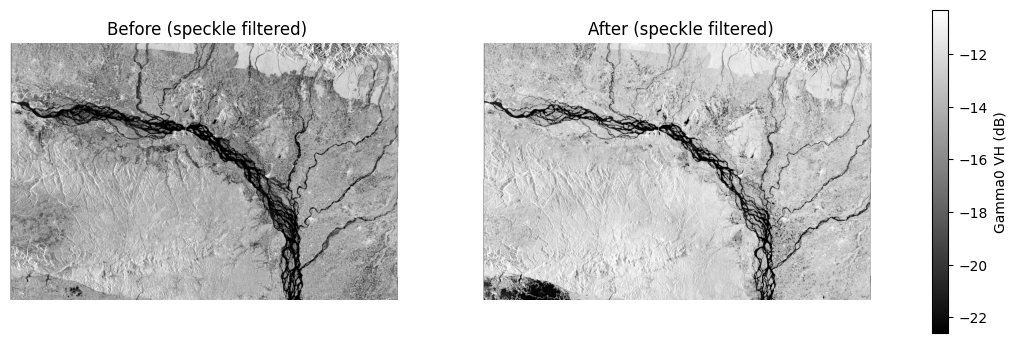

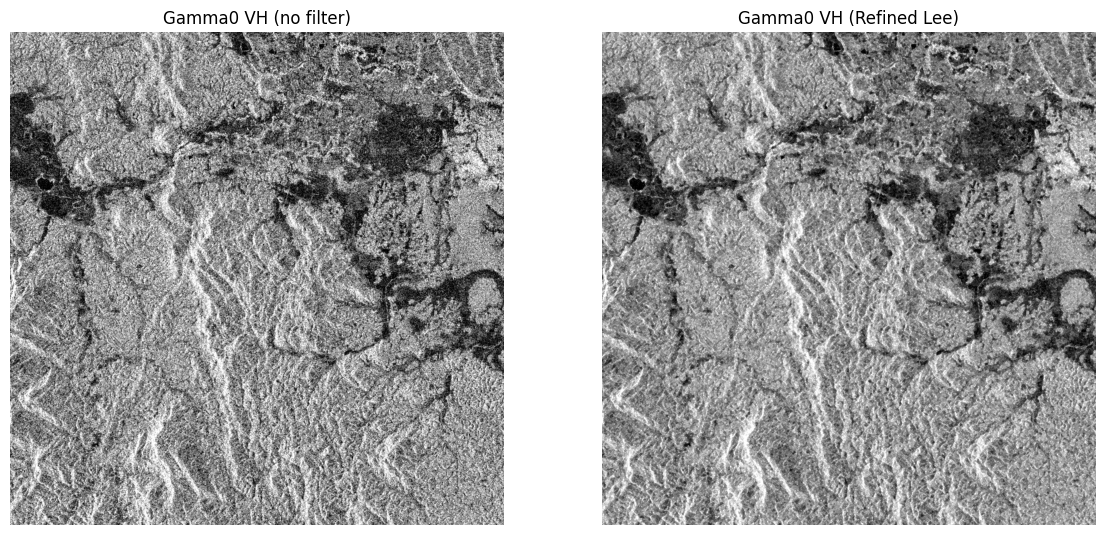

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

def img_path(dim_name, band="Gamma0_VH"):
    return f"{output_dir}/{dim_name}.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan
    return 10 * np.log10(arr)          # Gamma0 is linear power -> 10*log10

def read_overview(dim_name, scale=20):
    with rasterio.open(img_path(dim_name)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(dim_name, x, y, size=1500):
    with rasterio.open(img_path(dim_name)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

# ---------- 1. Overview: filtered before vs after ----------
b_spk = read_overview("before_speckle")
a_spk = read_overview("after_speckle")
vmin, vmax = np.nanpercentile(np.concatenate([b_spk.ravel(), a_spk.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_spk, a_spk], ["Before (speckle filtered)", "After (speckle filtered)"]):
    im = a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="Gamma0 VH (dB)")
plt.show()

# ---------- 2. Zoomed crop: unfiltered vs filtered (same window) ----------
with rasterio.open(img_path("before_speckle")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # center of the scene; change to look elsewhere

raw  = read_crop("before_gamma0",  x, y, size)
filt = read_crop("before_speckle", x, y, size)
vmin, vmax = np.nanpercentile(raw, [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [raw, filt], ["Gamma0 VH (no filter)", "Gamma0 VH (Refined Lee)"]):
    a.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step-3 Terrain Correction

In [ ]:
from esa_snappy import ProductIO
import os
output_dir = "/content/snap_outputs"
before_spk = ProductIO.readProduct(os.path.join(output_dir, "before_speckle.dim"))
after_spk  = ProductIO.readProduct(os.path.join(output_dir, "after_speckle.dim"))

In [ ]:
from esa_snappy import GPF, HashMap

tc_params_before = HashMap()

tc_params_before.put(
    "demName",
    "Copernicus 30m Global DEM" #glo30
)

tc_params_before.put(
    "pixelSpacingInMeter",
    10.0
)

tc_params_before.put(
    "mapProjection",
    "AUTO:42001"
)

tc_params_before.put(
    "sourceBands",
    "Gamma0_VH"
)

before_tc = GPF.createProduct(
    "Terrain-Correction",
    tc_params_before,
    before_spk
)

print("Before terrain correction completed.")
print("Product:", before_tc)

Before terrain correction completed.
Product: org.esa.snap.core.datamodel.Product[name=before_speckle_TC]


In [ ]:
tc_params_after = HashMap()

tc_params_after.put(
    "demName",
    "Copernicus 30m Global DEM"
)

tc_params_after.put(
    "pixelSpacingInMeter",
    10.0
)

tc_params_after.put(
    "mapProjection",
    "AUTO:42001"
)

tc_params_after.put(
    "sourceBands",
    "Gamma0_VH"
)

after_tc = GPF.createProduct(
    "Terrain-Correction",
    tc_params_after,
    after_spk
)

print("After terrain correction completed.")
print("Product:", after_tc)

After terrain correction completed.
Product: org.esa.snap.core.datamodel.Product[name=after_speckle_TC]


In [ ]:
before_tc_path = os.path.join(output_dir, "before_terrain_corrected.dim")
after_tc_path  = os.path.join(output_dir, "after_terrain_corrected.dim")

ProductIO.writeProduct(before_tc, before_tc_path, "BEAM-DIMAP")
ProductIO.writeProduct(after_tc, after_tc_path, "BEAM-DIMAP")

print("Before TC saved:", before_tc_path)
print("After TC saved :", after_tc_path)

Before TC saved: /content/snap_outputs/before_terrain_corrected.dim
After TC saved : /content/snap_outputs/after_terrain_corrected.dim


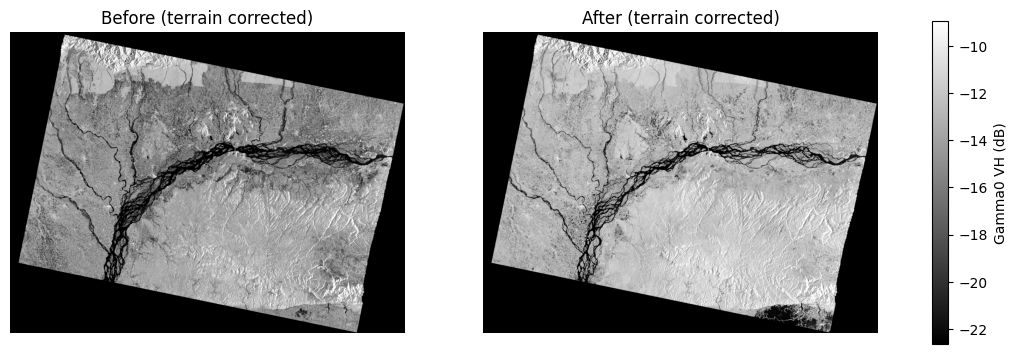

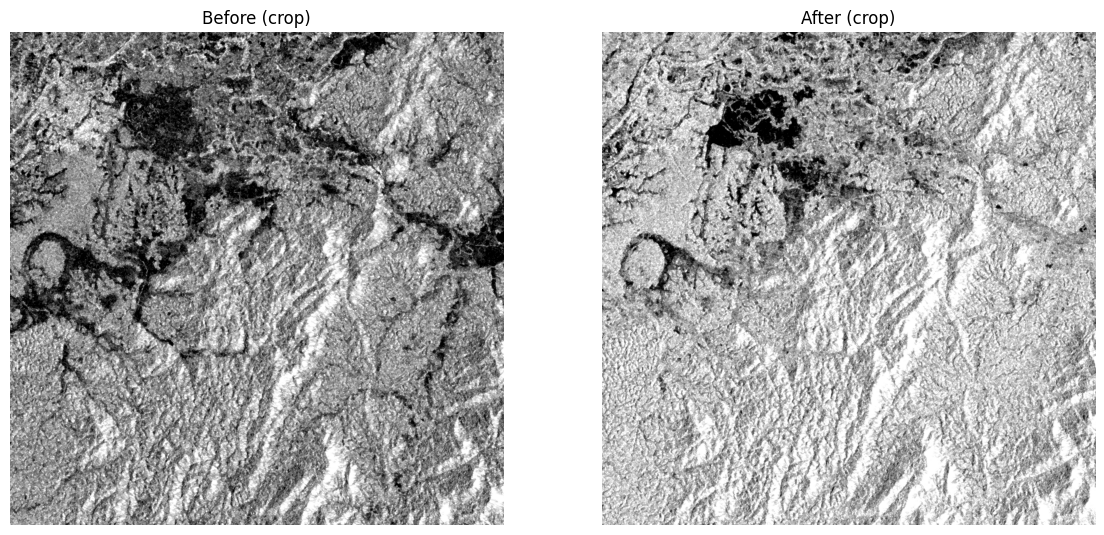

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"

def img_path(dim_name, band="Gamma0_VH"):
    return f"{output_dir}/{dim_name}.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan             # no-data outside the swath is 0
    return 10 * np.log10(arr)

def read_overview(dim_name, scale=20):
    with rasterio.open(img_path(dim_name)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(dim_name, x, y, size=1500):
    with rasterio.open(img_path(dim_name)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

# ---------- 1. Overview: terrain-corrected before vs after ----------
b_tc = read_overview("before_terrain_corrected")
a_tc = read_overview("after_terrain_corrected")
vmin, vmax = np.nanpercentile(np.concatenate([b_tc.ravel(), a_tc.ravel()]), [2, 98])

cmap = plt.get_cmap("gray").copy()
cmap.set_bad("black")                  # no-data area shown in black

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_tc, a_tc], ["Before (terrain corrected)", "After (terrain corrected)"]):
    im = a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="Gamma0 VH (dB)")
plt.show()

# ---------- 2. Zoomed crop at full 10 m resolution ----------
with rasterio.open(img_path("before_terrain_corrected")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # change to look elsewhere

b_crop = read_crop("before_terrain_corrected", x, y, size)
a_crop = read_crop("after_terrain_corrected",  x, y, size)
vmin, vmax = np.nanpercentile(b_crop, [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [b_crop, a_crop], ["Before (crop)", "After (crop)"]):
    a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step-4 Collocation

In [ ]:
# ============================================================
# Step 4: Collocation
# ============================================================
from esa_snappy import GPF, HashMap, ProductIO
import numpy as np, os

output_dir = "/content/snap_outputs"
os.makedirs(output_dir, exist_ok=True)

# Reload standalone (non-lazy) versions from disk — safe even if
# before_tc/after_tc were disposed or the runtime was restarted
before_tc = ProductIO.readProduct(os.path.join(output_dir, "before_terrain_corrected.dim"))
after_tc  = ProductIO.readProduct(os.path.join(output_dir, "after_terrain_corrected.dim"))

collocation_params = HashMap()
collocation_params.put("targetProductType", "COLLOCATED")
collocation_params.put("renameReferenceComponents", True)
collocation_params.put("renameSecondaryComponents", True)

collocated = GPF.createProduct("Collocate", collocation_params, [before_tc, after_tc])

print("Collocation bands:", list(collocated.getBandNames()))
# Expect: ['Gamma0_VH_M', 'Gamma0_VH_S', 'collocationFlags']

# Save collocated product
collocated_path = os.path.join(output_dir, "collocated.dim")
ProductIO.writeProduct(collocated, collocated_path, "BEAM-DIMAP")
print("Collocated saved:", collocated_path)

Collocation bands: ['Gamma0_VH_M', 'Gamma0_VH_S', 'collocationFlags']
Collocated saved: /content/snap_outputs/collocated.dim


['Gamma0_VH_M.hdr', 'Gamma0_VH_M.img', 'Gamma0_VH_S.hdr', 'Gamma0_VH_S.img', 'collocationFlags.hdr', 'collocationFlags.img', 'vector_data']


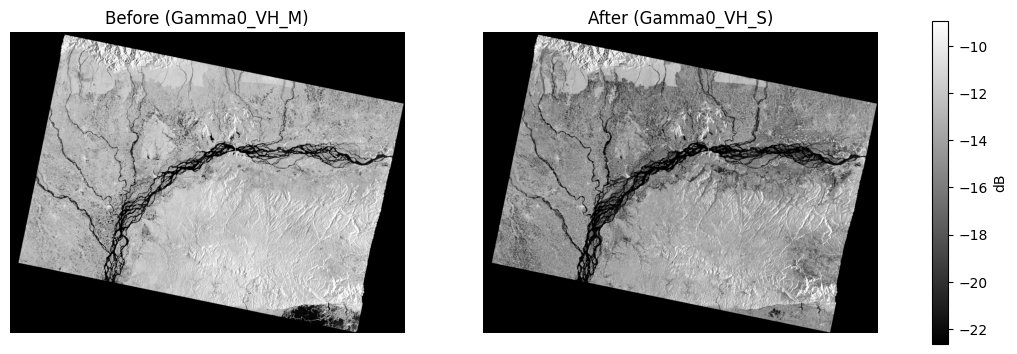

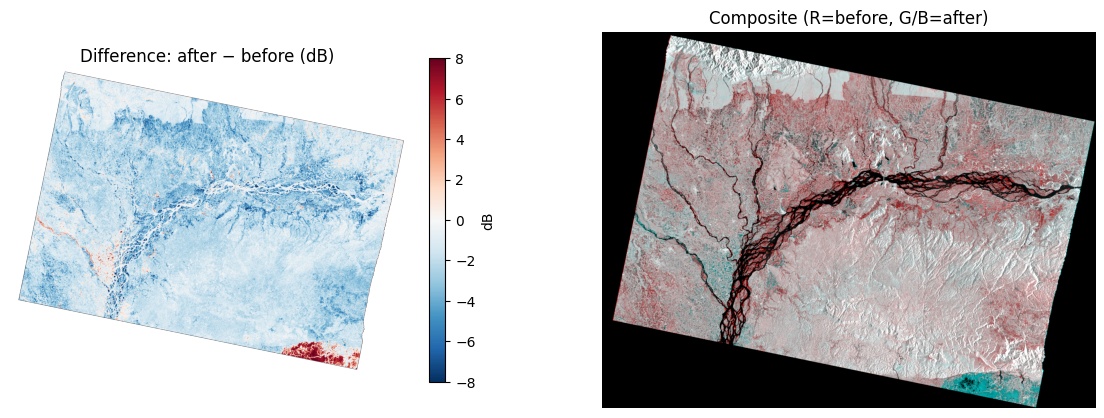

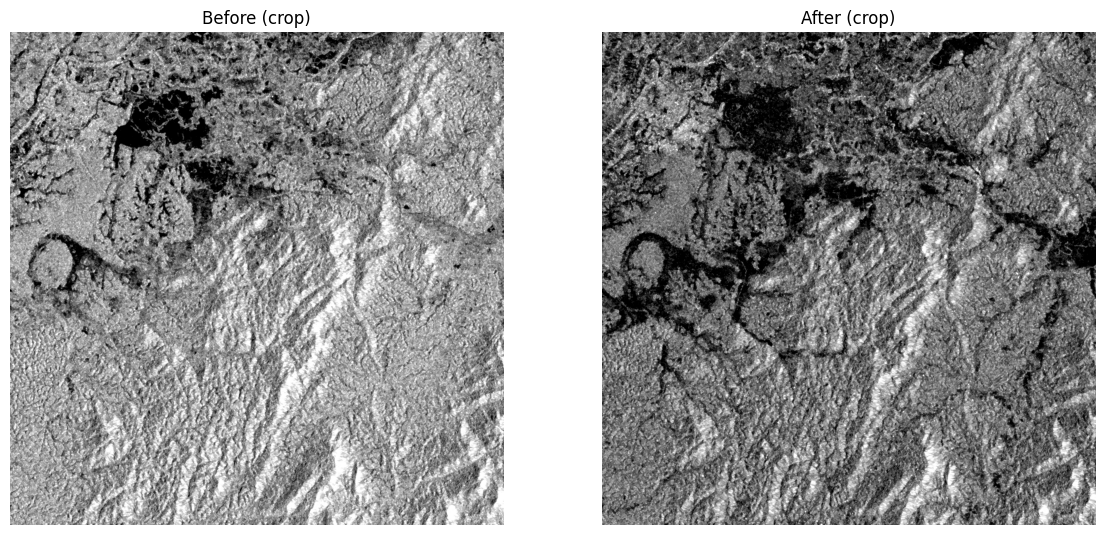

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"
print(sorted(os.listdir(f"{output_dir}/collocated.data")))   # check band files exist

def img_path(band):
    return f"{output_dir}/collocated.data/{band}.img"

def to_db(arr):
    arr = arr.astype("float32")
    arr[arr <= 0] = np.nan
    return 10 * np.log10(arr)

def read_overview(band, scale=20):
    with rasterio.open(img_path(band)) as src:
        h, w = src.height // scale, src.width // scale
        return to_db(src.read(1, out_shape=(h, w), resampling=Resampling.average))

def read_crop(band, x, y, size=1500):
    with rasterio.open(img_path(band)) as src:
        return to_db(src.read(1, window=Window(x, y, size, size)))

def stretch(a, lo=2, hi=98):
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1)

cmap = plt.get_cmap("gray").copy(); cmap.set_bad("black")

# ---------- 1. Before vs after on the SAME grid ----------
m = read_overview("Gamma0_VH_M")
s = read_overview("Gamma0_VH_S")
vmin, vmax = np.nanpercentile(np.concatenate([m.ravel(), s.ravel()]), [2, 98])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [m, s], ["Before (Gamma0_VH_M)", "After (Gamma0_VH_S)"]):
    im = a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.6, label="dB")
plt.show()

# ---------- 2. Difference (after - before) and RGB change composite ----------
diff = s - m                                   # negative = got darker = possible flooding
rgb = np.dstack([stretch(m), stretch(s), stretch(s)])   # R=before, G=after, B=after
rgb[np.isnan(rgb)] = 0

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
im = ax[0].imshow(diff, cmap="RdBu_r", vmin=-8, vmax=8)
ax[0].set_title("Difference: after − before (dB)"); ax[0].axis("off")
fig.colorbar(im, ax=ax[0], shrink=0.6, label="dB")
ax[1].imshow(rgb)
ax[1].set_title("Composite (R=before, G/B=after)"); ax[1].axis("off")
plt.show()

# ---------- 3. Full-resolution crop ----------
with rasterio.open(img_path("Gamma0_VH_M")) as src:
    W, H = src.width, src.height
size = 1500
x, y = W // 2 - size // 2, H // 2 - size // 2      # move toward the river to see flooding

mc, sc = read_crop("Gamma0_VH_M", x, y, size), read_crop("Gamma0_VH_S", x, y, size)
vmin, vmax = np.nanpercentile(mc, [2, 98])
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, img, t in zip(ax, [mc, sc], ["Before (crop)", "After (crop)"]):
    a.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    a.set_title(t); a.axis("off")
plt.show()

Step 5: Convert Gamma0 linear -> dB

In [ ]:
from esa_snappy import GPF, HashMap, ProductIO
db_params = HashMap()
db_params.put("sourceBands", "Gamma0_VH_M,Gamma0_VH_S")

collocated_db = GPF.createProduct("LinearToFromdB", db_params, collocated)

db_band_names = list(collocated_db.getBandNames())
print("dB-converted bands:", db_band_names)
# SNAP appends a "_db" suffix, e.g. ['Gamma0_VH_M_db', 'Gamma0_VH_S_db', 'collocationFlags']

# Save collocated_db product
collocated_db_path = os.path.join(output_dir, "collocated_db.dim")
ProductIO.writeProduct(collocated_db, collocated_db_path, "BEAM-DIMAP")
print("Collocated dB saved:", collocated_db_path)

dB-converted bands: ['Gamma0_VH_M_db', 'Gamma0_VH_S_db', 'collocationFlags']
Collocated dB saved: /content/snap_outputs/collocated_db.dim


In [ ]:
import numpy as np
from esa_snappy import ProductIO

product = ProductIO.readProduct(
    "/content/snap_outputs/collocated_db.dim"
)

for band_name in ["Gamma0_VH_M_db", "Gamma0_VH_S_db"]:
    band = product.getBand(band_name)
    width = band.getRasterWidth()
    height = band.getRasterHeight()

    tile_height = 2000  # adjust down if it still errors
    running_min, running_max, running_sum, running_count = np.inf, -np.inf, 0.0, 0

    for y in range(0, height, tile_height):
        h = min(tile_height, height - y)
        tile = np.zeros(width * h, dtype=np.float32)
        band.readPixels(0, y, width, h, tile)

        valid = tile[np.isfinite(tile)]
        if valid.size == 0:
            continue

        running_min = min(running_min, valid.min())
        running_max = max(running_max, valid.max())
        running_sum += valid.sum()
        running_count += valid.size

        del tile, valid  # free the tile before the next loop

    print("\n", band_name)
    print("min:", running_min)
    print("max:", running_max)
    print("mean:", running_sum / running_count if running_count else None)
    print("non-zero pixels:", running_count)


 Gamma0_VH_M_db
min: -29.893633
max: 16.529713
mean: -9.158472
non-zero pixels: 631659449

 Gamma0_VH_S_db
min: -30.955132
max: 15.992213
mean: -10.400211
non-zero pixels: 631659449


Checking statistics for difference

In [ ]:
import numpy as np
from esa_snappy import ProductIO

product = ProductIO.readProduct(
    "/content/snap_outputs/collocated_db.dim"
)

band_m = product.getBand("Gamma0_VH_M_db")
band_s = product.getBand("Gamma0_VH_S_db")
width = band_m.getRasterWidth()
height = band_m.getRasterHeight()

tile_height = 2000  # lower this (e.g. 500-1000) if it still crashes
diff_min, diff_max, diff_sum, diff_count, nonzero_count, gt3_count = np.inf, -np.inf, 0.0, 0, 0, 0

for y in range(0, height, tile_height):
    h = min(tile_height, height - y)

    m = np.zeros(width * h, dtype=np.float32)
    s = np.zeros(width * h, dtype=np.float32)
    band_m.readPixels(0, y, width, h, m)
    band_s.readPixels(0, y, width, h, s)

    diff = np.abs(m - s)

    diff_min = min(diff_min, diff.min())
    diff_max = max(diff_max, diff.max())
    diff_sum += diff.sum()
    diff_count += diff.size
    nonzero_count += np.count_nonzero(diff)
    gt3_count += np.count_nonzero(diff > 3)

    del m, s, diff

print("Difference:")
print("min:", diff_min)
print("max:", diff_max)
print("mean:", diff_sum / diff_count)
print("non-zero:", nonzero_count)
print("pixels > 3 dB:", gt3_count)

Difference:
min: 0.0
max: 26.965466
mean: 1.7291312
non-zero: 426687330
pixels > 3 dB: 144512757


Step 6: Change magnitude on the dB bands (BandMaths, replaces CVA)

In [ ]:
import os
from esa_snappy import ProductIO, GPF, HashMap
import jpy

output_dir = "/content/snap_outputs"

# Reload standalone version from disk — safe even after a restart
collocated_db = ProductIO.readProduct(os.path.join(output_dir, "collocated_db.dim"))
db_band_names = list(collocated_db.getBandNames())
band1_name = [b for b in db_band_names if "_M_db" in b][0]
band2_name = [b for b in db_band_names if "_S_db" in b][0]

BandDescriptor = jpy.get_type('org.esa.snap.core.gpf.common.BandMathsOp$BandDescriptor')

target_band = BandDescriptor()
target_band.name = "magnitude"
target_band.type = "float32"
target_band.expression = f"abs({band1_name} - {band2_name})"

target_bands = jpy.array('org.esa.snap.core.gpf.common.BandMathsOp$BandDescriptor', 1)
target_bands[0] = target_band

bm_params = HashMap()
bm_params.put("targetBands", target_bands)

bm_sources = HashMap()
bm_sources.put("sourceProduct", collocated_db)

cva = GPF.createProduct("BandMaths", bm_params, bm_sources)
print("Magnitude bands:", list(cva.getBandNames()))   # ['magnitude']

# Save product
cva_path = os.path.join(output_dir, "cva.dim")
ProductIO.writeProduct(cva, cva_path, "BEAM-DIMAP")
print("Magnitude product saved:", cva_path)

Magnitude bands: ['magnitude']
Magnitude product saved: /content/snap_outputs/cva.dim


['magnitude.hdr', 'magnitude.img', 'vector_data']


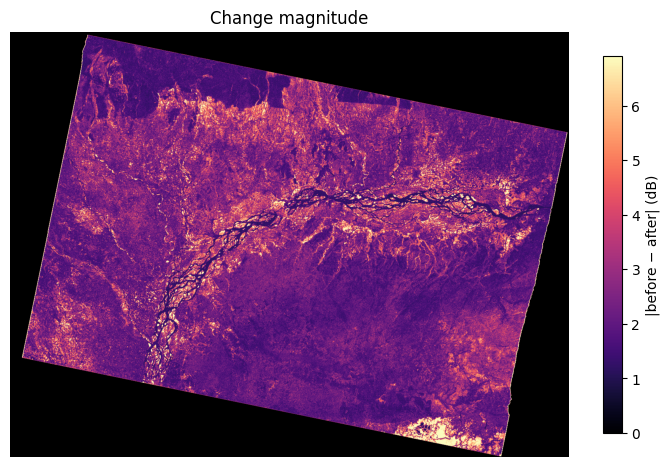

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

output_dir = "/content/snap_outputs"
print(sorted(os.listdir(f"{output_dir}/cva.data")))   # should include magnitude.img

mag_path = f"{output_dir}/cva.data/magnitude.img"

def clean(arr):
    arr = arr.astype("float32")
    arr[arr == 0] = np.nan          # no-data border: |0 - 0| = 0 exactly
    return arr

cmap = plt.get_cmap("magma").copy()
cmap.set_bad("black")

# ---------- 1. Overview map ----------
scale = 20
with rasterio.open(mag_path) as src:
    W, H = src.width, src.height
    mag = clean(src.read(1, out_shape=(H // scale, W // scale), resampling=Resampling.average))

plt.figure(figsize=(9, 7))
im = plt.imshow(mag, cmap=cmap, vmin=0, vmax=np.nanpercentile(mag, 99))
plt.colorbar(im, shrink=0.7, label="|before − after| (dB)")
plt.title("Change magnitude"); plt.axis("off"); plt.show()

Step 7: K-Means clustering on the magnitude band (3 clusters)

In [ ]:
import os
import json
import numpy as np
import rasterio
from rasterio.warp import transform as warp_transform
from esa_snappy import ProductIO, PixelPos
from sklearn.cluster import MiniBatchKMeans

output_dir = "/content/snap_outputs"
N_CLUSTERS = 3
tile_height = 2000
NODATA = 255

# ------------------------------------------------------------
# 1. Reload magnitude product from disk
# ------------------------------------------------------------
cva = ProductIO.readProduct(os.path.join(output_dir, "cva.dim"))
if "magnitude" not in cva.getBandNames():
    raise ValueError(
        f"'magnitude' band not found — got {list(cva.getBandNames())}. "
        "Re-run Step 6 (BandMaths) before this cell."
    )

mag_band = cva.getBand("magnitude")
width = mag_band.getRasterWidth()
height = mag_band.getRasterHeight()

# ------------------------------------------------------------
# 2. Georeferencing (needed so kmeans.tif is a valid GeoTIFF)
# ------------------------------------------------------------
gc = cva.getSceneGeoCoding()
crs_wkt = gc.getMapCRS().toWKT()
ul = gc.getGeoPos(PixelPos(0, 0), None)
lr = gc.getGeoPos(PixelPos(width, height), None)
xs, ys = warp_transform("EPSG:4326", crs_wkt, [ul.lon, lr.lon], [ul.lat, lr.lat])
transform = rasterio.transform.from_bounds(xs[0], ys[1], xs[1], ys[0], width, height)
print("Pixel size (m):", transform.a)

# ------------------------------------------------------------
# 3. Sample the magnitude band and fit K-Means
# ------------------------------------------------------------
np.random.seed(31415)
sample_values = []
max_sample_pixels = 5_000_000
n_tiles = (height + tile_height - 1) // tile_height

for y in range(0, height, tile_height):
    h = min(tile_height, height - y)
    tile = np.zeros(width * h, dtype=np.float32)
    mag_band.readPixels(0, y, width, h, tile)
    valid = tile[np.isfinite(tile)]
    if valid.size:
        keep = min(valid.size, max(1, max_sample_pixels // n_tiles))
        idx = np.random.choice(valid.size, size=keep, replace=False)
        sample_values.append(valid[idx])
    del tile, valid

sample = np.concatenate(sample_values).reshape(-1, 1)
print("Fitting KMeans on", sample.shape[0], "sample pixels...")

kmeans = MiniBatchKMeans(n_clusters=N_CLUSTERS, random_state=31415, n_init=10)
kmeans.fit(sample)

centers = kmeans.cluster_centers_.ravel()

# Rank clusters by center value (ascending)
order = np.argsort(centers)
land_cluster_id  = int(order[0])   # lowest magnitude  = permanent land
water_cluster_id = int(order[1])   # middle magnitude  = permanent water
flood_cluster_id = int(order[2])   # highest magnitude = flooded

class_tags = {
    land_cluster_id:  "  <- permanent land",
    water_cluster_id: "  <- permanent water",
    flood_cluster_id: "  <- flood class",
}

print("\nCluster centers (dB magnitude):")
unique, counts = np.unique(kmeans.labels_, return_counts=True)
for u, c in zip(unique, counts):
    tag = class_tags.get(int(u), "")
    print(f"  class_{u}: center={centers[u]:.2f} dB, {c} pixels ({100*c/kmeans.labels_.size:.1f}% of sample){tag}")

# Save cluster info to disk so Step 8 can run independently, even after a restart
with open(os.path.join(output_dir, "kmeans_meta.json"), "w") as f:
    json.dump({
        "land_cluster_id": land_cluster_id,
        "water_cluster_id": water_cluster_id,
        "flood_cluster_id": flood_cluster_id,
        "centers": centers.tolist(),
    }, f)

# ------------------------------------------------------------
# 4. Apply the fitted model tile-by-tile, write class labels to GeoTIFF
# ------------------------------------------------------------
kmeans_path = os.path.join(output_dir, "kmeans.tif")

with rasterio.open(
    kmeans_path, "w",
    driver="GTiff", height=height, width=width,
    count=1, dtype="uint8", crs=crs_wkt, transform=transform,
    nodata=NODATA,
) as dst:
    for y in range(0, height, tile_height):
        h = min(tile_height, height - y)
        tile = np.zeros(width * h, dtype=np.float32)
        mag_band.readPixels(0, y, width, h, tile)

        labels = np.full(tile.shape, NODATA, dtype=np.uint8)  # 255 = nodata
        finite_mask = np.isfinite(tile)
        if finite_mask.any():
            labels[finite_mask] = kmeans.predict(tile[finite_mask].reshape(-1, 1)).astype(np.uint8)

        dst.write(labels.reshape(h, width), 1, window=((y, y + h), (0, width)))
        del tile, labels, finite_mask

print("\nK-Means class map saved:", kmeans_path)
print(f"Land ID: {land_cluster_id} | Water ID: {water_cluster_id} | Flood ID: {flood_cluster_id} (saved to kmeans_meta.json)")

Pixel size (m): 10.000000000204222
Fitting KMeans on 4999995 sample pixels...

Cluster centers (dB magnitude):
  class_0: center=0.34 dB, 2919947 pixels (58.4% of sample)  <- permanent land
  class_1: center=6.17 dB, 534023 pixels (10.7% of sample)  <- flood class
  class_2: center=2.80 dB, 1546025 pixels (30.9% of sample)  <- permanent water

K-Means class map saved: /content/snap_outputs/kmeans.tif
Land ID: 0 | Water ID: 2 | Flood ID: 1 (saved to kmeans_meta.json)



Step 8: Build final flood mask + export deliverable GeoTIFFs

In [ ]:
import os
import json
import numpy as np
import rasterio

output_dir = "/content/snap_outputs"
NODATA = 255  # must match Step 7

# ------------------------------------------------------------
# 1. Load Step 7's output + cluster metadata (works after a restart too)
# ------------------------------------------------------------
kmeans_path = os.path.join(output_dir, "kmeans.tif")
meta_path = os.path.join(output_dir, "kmeans_meta.json")

if not os.path.exists(kmeans_path) or not os.path.exists(meta_path):
    raise FileNotFoundError("kmeans.tif or kmeans_meta.json not found — re-run Step 7 first.")

with open(meta_path) as f:
    meta = json.load(f)
flood_cluster_id = meta["flood_cluster_id"]
land_cluster_id = meta.get("land_cluster_id")
water_cluster_id = meta.get("water_cluster_id")
print(f"Flood ID: {flood_cluster_id} | Land ID: {land_cluster_id} | Water ID: {water_cluster_id}")
print("Centers:", meta["centers"])

# ------------------------------------------------------------
# 2. Build the binary flood mask: white (255) = flooded, black (0) = everything else
#    (matches the manual: "Set Black to other classes, White to the Flooded region")
# ------------------------------------------------------------
flood_mask_path = os.path.join(output_dir, "flood_mask.tif")

with rasterio.open(kmeans_path) as src:
    profile = src.profile.copy()
    # nodata must be cleared: 255 is the "flooded" value in this mask
    profile.update(dtype="uint8", count=1, tiled=False, nodata=None)
    profile.pop("blockxsize", None)
    profile.pop("blockysize", None)

    with rasterio.open(flood_mask_path, "w", **profile) as dst:
        for _, window in src.block_windows(1):
            class_tile = src.read(1, window=window)
            mask_tile = np.where(class_tile == flood_cluster_id, 255, 0).astype(np.uint8)
            dst.write(mask_tile, 1, window=window)

print("Final flood mask saved:", flood_mask_path)

# ------------------------------------------------------------
# 3. Quick stats (valid pixels only, nodata excluded)
# ------------------------------------------------------------
with rasterio.open(kmeans_path) as src:
    valid = 0
    flooded = 0
    nodata_px = 0
    for _, window in src.block_windows(1):
        block = src.read(1, window=window)
        is_nodata = block == NODATA
        nodata_px += np.count_nonzero(is_nodata)
        valid += block.size - np.count_nonzero(is_nodata)
        flooded += np.count_nonzero(block == flood_cluster_id)

print(f"Nodata pixels (excluded): {nodata_px}")
print(f"Flooded pixels: {flooded} / {valid} valid ({100*flooded/valid:.2f}%)")

# ------------------------------------------------------------
# 4. Export supporting deliverables — use BigTIFF for large products
#    (as requested in the assignment: collocated + magnitude products)
# ------------------------------------------------------------
from esa_snappy import ProductIO

for var_name in ["collocated_db", "cva"]:
    if var_name not in dir():
        print(f"Note: '{var_name}' not in this session — reloading from disk for export.")

try:
    if "collocated_db" not in dir():
        collocated_db = ProductIO.readProduct(os.path.join(output_dir, "collocated_db.dim"))
    ProductIO.writeProduct(
        collocated_db,
        os.path.join(output_dir, "collocated_db_final.tif"),
        "GeoTIFF-BigTIFF"
    )
    print("Saved: collocated_db_final.tif")
except Exception as e:
    print("FAILED writing collocated_db_final.tif:", e)

try:
    if "cva" not in dir():
        cva = ProductIO.readProduct(os.path.join(output_dir, "cva.dim"))
    ProductIO.writeProduct(
        cva,
        os.path.join(output_dir, "change_vector_analysis.tif"),
        "GeoTIFF-BigTIFF"
    )
    print("Saved: change_vector_analysis.tif")
except Exception as e:
    print("FAILED writing change_vector_analysis.tif:", e)

print("\n=== Final deliverables in", output_dir, "===")
for fname in ["collocated_db_final.tif", "change_vector_analysis.tif", "kmeans.tif", "flood_mask.tif"]:
    path = os.path.join(output_dir, fname)
    print(f"  {'✓' if os.path.exists(path) else '✗ MISSING'}  {fname}")

Flood ID: 1 | Land ID: 0 | Water ID: 2
Centers: [0.3399028182029724, 6.173655986785889, 2.7994818687438965]
Final flood mask saved: /content/snap_outputs/flood_mask.tif
Nodata pixels (excluded): 0
Flooded pixels: 67557973 / 631659449 valid (10.70%)
Saved: collocated_db_final.tif
Saved: change_vector_analysis.tif

=== Final deliverables in /content/snap_outputs ===
  ✓  collocated_db_final.tif
  ✓  change_vector_analysis.tif
  ✓  kmeans.tif
  ✓  flood_mask.tif


In [ ]:
import shutil
import os

output_dir = "/content/snap_outputs"
drive_dest = "/content/drive/MyDrive/snap_outputs_30SEPT"  # change folder name if you want

os.makedirs(drive_dest, exist_ok=True)

files_to_copy = [
    "collocated_db_final.tif",
    "change_vector_analysis.tif",
    "kmeans.tif",
    "flood_mask.tif",
]

for fname in files_to_copy:
    src = os.path.join(output_dir, fname)
    dst = os.path.join(drive_dest, fname)
    if os.path.exists(src):
        shutil.copy(src, dst)
        print(f"Copied: {fname} ({os.path.getsize(src) / 1e9:.2f} GB)")
    else:
        print(f"Missing, skipped: {fname}")

print("\nDone. Files are in your Drive under 'snap_outputs'.")

Copied: collocated_db_final.tif (4.04 GB)
Copied: change_vector_analysis.tif (1.87 GB)
Copied: kmeans.tif (0.63 GB)
Copied: flood_mask.tif (0.63 GB)

Done. Files are in your Drive under 'snap_outputs'.


Step 9 : Morphology

In [ ]:
import os, shutil
import numpy as np
import rasterio
from rasterio.windows import Window
from scipy import ndimage as ndi
from skimage.morphology import disk

# ------------------------------------------------------------
# 1. Mount Drive (safe to re-run if already mounted)
# ------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

drive_dir = "/content/drive/MyDrive/snap_outputs_30SEPT"    # change if your folder name differs
drive_in  = os.path.join(drive_dir, "flood_mask.tif")
drive_out = os.path.join(drive_dir, "flood_mask_clean.tif")

if not os.path.exists(drive_in):
    raise FileNotFoundError(f"Not found: {drive_in}\nFiles in folder: {os.listdir(drive_dir) if os.path.exists(drive_dir) else 'folder missing'}")

# ------------------------------------------------------------
# 2. Copy to local disk for faster tile-wise reading
# ------------------------------------------------------------
work_dir = "/content/morph_work"
os.makedirs(work_dir, exist_ok=True)
in_path  = os.path.join(work_dir, "flood_mask.tif")
out_path = os.path.join(work_dir, "flood_mask_clean.tif")

shutil.copy(drive_in, in_path)
print(f"Copied input ({os.path.getsize(in_path) / 1e9:.2f} GB)")

# ---- tunable parameters ----
# ---- original morphology settings ----
OPEN_RADIUS  = 3      # removes specks ~2-3 px wide
CLOSE_RADIUS = 5      # fills small gaps/holes
MIN_AREA_PX  = 500    # 100 px * 100 m² = 1 ha
MIN_HOLE_PX  = 300      # 0 = hole filling off (original code had none)
MAJORITY_K   = 5      # 0 = majority filter off (original code had none)
tile_height  = 2000
halo         = 64     # fine to leave as is; a larger halo only reads a few extra rows

def remove_small(m, min_px):
    """Drop connected blobs smaller than min_px. Blobs touching the tile
    border are kept, since their true size is unknown (they continue into the next tile)."""
    lab, n = ndi.label(m)
    if n == 0:
        return m
    sizes = np.bincount(lab.ravel())
    border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    keep = sizes >= min_px
    keep[border] = True
    keep[0] = False                      # label 0 = background
    return keep[lab]

def clean_mask(m):
    m = ndi.binary_opening(m, structure=disk(OPEN_RADIUS))     # kill specks
    m = ndi.binary_closing(m, structure=disk(CLOSE_RADIUS))    # bridge gaps
    m = remove_small(m, MIN_AREA_PX)                           # drop small flood blobs
    m = ~remove_small(~m, MIN_HOLE_PX)                         # fill small holes
    if MAJORITY_K:                                             # smooth ragged edges
        m = ndi.uniform_filter(m.astype(np.float32), size=MAJORITY_K) > 0.5
    return m
# ------------------------------------------------------------
# 3. Apply morphology tile by tile
# ------------------------------------------------------------
with rasterio.open(in_path) as src:
    profile = src.profile.copy()
    width, height = src.width, src.height
    profile.update(dtype="uint8", count=1, compress="lzw")

    before_px, after_px = 0, 0
    with rasterio.open(out_path, "w", **profile) as dst:
        for y in range(0, height, tile_height):
            h = min(tile_height, height - y)

            y0 = max(0, y - halo)
            y1 = min(height, y + h + halo)
            block = src.read(1, window=Window(0, y0, width, y1 - y0)) > 0

            cleaned = clean_mask(block)

            top = y - y0
            interior = cleaned[top:top + h]

            before_px += int(block[top:top + h].sum())
            after_px  += int(interior.sum())

            dst.write(interior.astype(np.uint8) * np.uint8(255), 1,
                      window=Window(0, y, width, h))

print(f"Flooded pixels before: {before_px}  ->  after: {after_px} "
      f"({100*(before_px-after_px)/max(before_px,1):.1f}% removed)")

# ------------------------------------------------------------
# 4. Save the cleaned mask back to Drive
# ------------------------------------------------------------
shutil.copy(out_path, drive_out)
print("Saved to Drive:", drive_out)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Copied input (0.63 GB)
Flooded pixels before: 67557973  ->  after: 19204180 (71.6% removed)
Saved to Drive: /content/drive/MyDrive/snap_outputs_30SEPT/flood_mask_clean.tif
